# PART 9. 판매자 이탈 예측 (분류 · 로지스틱 회귀 vs 랜덤 포레스트)

> **핵심 질문: 최근까지 판매하던 판매자 중, 앞으로 3개월 동안 주문을 받지 못할 판매자는 누구일까?**

## 📋 한눈에 보기

**작업 흐름**
```
1. 기준일(2018-06-01) 이전으로 특징, 이후 3개월로 이탈 정답 만들기
2. test 먼저 떼어 두기
3. 규칙 베이스라인 (최근 N일 판매 없음)
4. 로지스틱 회귀 · 랜덤 포레스트 × class_weight 전후
5. 5-fold 교차검증으로 비교
6. test로 최종 평가 · 해석
7. PART 8 유형별 이탈률
8. 배포용 저장
```

| 항목 | 내용 |
|---|---|
| 사용 데이터 | 원본 CSV → 2018-03~05 활동 판매자 1,567명 (이탈 24.1%) |
| 결과물 | `part9_seller_churn.pkl` (약 2KB, 로지스틱 회귀) |

**🎯 핵심 (꼭 가져갈 것)**
- 이탈은 실제 폐업이 아니라 **'3개월 주문 없음'이라는 실습용 정의**입니다.
- 머신러닝 전에 **단순한 규칙**과 먼저 비교합니다. 데이터가 작으면 **교차검증**으로 비교합니다.

**💡 인사이트 (이 파트에서 확인한 사실)**
- 규칙(최근 30일 판매 없음)도 F1 0.53으로 꽤 잘 맞습니다.
- class_weight를 쓰면 재현율이 약 0.3 → 0.75로 크게 오릅니다.
- 로지스틱 회귀(F1 0.58)는 5번 모두 규칙보다 높았습니다. 유형별 이탈률은 핵심 우량 17% ~ 저평점 위험 66%입니다.

---

## 수업 목표
- **이탈**을 데이터로 정의하고, 과거(특징)와 미래(정답)를 시간으로 나눠 학습 데이터를 만듭니다.
- 단순한 **규칙**을 먼저 만들고, 머신러닝이 정말 나은지 비교합니다.
- **불균형 데이터**에서 `class_weight`가 결과를 어떻게 바꾸는지 확인합니다.
- 작은 데이터에서는 **교차검증**으로 비교해야 하는 이유를 이해합니다.

## 수업 진행 포인트
| 구분 | 설명 |
|---|---|
| 데이터 관점 | 판매자 1명 = 1행. 기준일 이전 정보로 특징을, 이후 3개월로 정답을 만듭니다. |
| 코드 관점 | `Pipeline`, `cross_validate`, `class_weight`, `classification_report`, `confusion_matrix` 사용법을 익힙니다. |
| AI 관점 | 지도 학습(분류)의 표준 흐름입니다. 정확도가 아니라 **재현율·F1**로 평가합니다. |

## 왜 고객이 아니라 판매자일까?
| EDA 결과 (PART 5) | 그래서 |
|---|---|
| 인사이트 1. 고객의 약 97%가 한 번만 구매 | 고객은 거의 전부 "이탈"이라 예측할 거리가 없습니다. 모델이 "전부 이탈"만 찍어도 정확도가 97%입니다. |
| 판매자는 매달 반복해서 판매 | "판매를 멈췄다"는 정의가 자연스럽고, 이탈과 유지가 적당히 섞여 있습니다. |

---

## 📌 이 파트에서 사용하는 API 흐름 (scikit-learn)

| 단계 | 함수 | 역할 |
|---|---|---|
| ① | `train_test_split(stratify=y)` | 시험지(test)를 먼저 떼어 두기 |
| ② | `Pipeline([결측 채우기, 스케일링, 모델])` | 전처리와 모델을 한 덩어리로 |
| ③ | `cross_validate(cv=5)` | train 안에서 5번 나눠 평가 → 평균과 흔들림 확인 |
| ④ | `fit()` → `predict()` / `predict_proba()` | 최종 학습과 예측 |
| ⑤ | `classification_report`, `confusion_matrix` | 시험지로 최종 평가 |
| ⑥ | `joblib.dump()` | 배포용 저장 |

## 핵심 개념

| 개념 | 설명 |
|---|---|
| 이탈 (이 실습의 정의) | 기준일 직전 3개월에 판매가 있었는데, 이후 3개월 동안 유효 주문이 0건 |
| 데이터 누수 | 예측 시점에 알 수 없는 미래 정보가 특징에 섞이는 것 |
| 불균형 데이터 | 한쪽 정답(유지)이 훨씬 많은 데이터. 정확도만 보면 속기 쉬움 |
| class_weight | 적은 쪽(이탈)을 틀리면 벌점을 더 크게 줘서 불균형을 보정 |
| 교차검증 | 데이터를 여러 번 다르게 나눠 평가하고 평균을 내는 방법 |
| 재현율 (Recall) | 실제 이탈 판매자 중 모델이 찾아낸 비율 |
| 정밀도 (Precision) | 모델이 이탈이라고 한 판매자 중 실제 이탈 비율 |

In [1]:
# 셀 1. Google Drive 연결

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 셀 2. 라이브러리 불러오기

# 그래프 한글 깨짐 방지 (Colab에는 한글 폰트가 없어서 □□□로 표시됨)
!pip install -q koreanize-matplotlib

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # import만 하면 한글 폰트가 자동 적용됩니다
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)

base_path  = "/content/drive/MyDrive/Colab Notebooks/Data_Analysis/Olist"
data_path  = f"{base_path}/data"     # PART 2에서 저장한 원본 CSV 위치
model_path = f"{base_path}/model"    # 학습한 모델을 저장할 위치
os.makedirs(model_path, exist_ok=True)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("경로 설정 완료!")

경로 설정 완료!


---
## 1. 학습 데이터 만들기

### 이탈의 정의 (시간으로 나누기)

| 구간 | 기간 | 역할 |
|---|---|---|
| 관찰 구간 | 2017-01 ~ 2018-05 | 특징(X)을 만드는 데 사용 |
| 활동 확인 | 2018-03 ~ 2018-05 | 이 기간에 유효 주문이 1건 이상인 판매자만 대상 |
| 예측 구간 | 2018-06 ~ 2018-08 | 유효 주문 0건이면 **이탈(1)**, 1건 이상이면 **유지(0)** |

- **유효 주문** = 취소(canceled) · 구매 불가(unavailable)를 뺀 주문
- 이미 판매를 멈춘 판매자는 대상에서 뺍니다. "멈춘 사람이 멈출 것"을 맞히는 건 의미가 없기 때문입니다. **최근 활동한 판매자의 향후 주문 중단**을 예측합니다.

> ⚠️ 원본 데이터는 2018-08-29에 끝나고, 8월 하순부터 주문이 급격히 줄어듭니다(데이터 수집 종료). 그래서 예측 구간은 실제로는 약 2.8개월이고, 8월 말에 주문했을 판매자 일부가 이탈로 잡혔을 수 있습니다.

In [3]:
# 셀 3. 원본 데이터 불러오기

date_cols = ["order_purchase_timestamp", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders  = pd.read_csv(f"{data_path}/olist_orders_dataset.csv", parse_dates=date_cols)
items   = pd.read_csv(f"{data_path}/olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
reviews = pd.read_csv(f"{data_path}/olist_order_reviews_dataset.csv", parse_dates=["review_creation_date"])
sellers = pd.read_csv(f"{data_path}/olist_sellers_dataset.csv")

print(f"주문 {len(orders):,}건 / 판매 상품 {len(items):,}행 / 리뷰 {len(reviews):,}건 / 판매자 {len(sellers):,}명")

주문 99,441건 / 판매 상품 112,650행 / 리뷰 99,224건 / 판매자 3,095명


In [4]:
# 셀 4. 판매자 프로필 함수 (판매자 1명 = 1행)
# ⚠️ 기준일(cutoff) '이전'에 알 수 있었던 정보만 사용합니다.
#    - 기준일 전에 들어온 주문만
#    - 배송 완료·출고 시각도 기준일 전에 일어난 것만
#    - 리뷰도 기준일 전에 작성된 것만
# PART 8 · PART 9 · PART 10(배포)에서 똑같은 함수를 씁니다.

def make_seller_profile(orders, items, reviews, cutoff, start="2017-01-01"):
    cutoff = pd.Timestamp(cutoff)
    o = orders[
        (orders["order_purchase_timestamp"] >= start)
        & (orders["order_purchase_timestamp"] < cutoff)
        & ~orders["order_status"].isin(["canceled", "unavailable"])   # 유효 주문만
    ]
    line = items.merge(o, on="order_id")

    # 판매자-주문 단위로 정리 (한 주문에 같은 판매자 상품이 여러 개면 1행으로)
    so = line.groupby(["seller_id", "order_id"]).agg(
        purchase=("order_purchase_timestamp", "first"),
        carrier=("order_delivered_carrier_date", "first"),     # 택배사에 넘긴 시각 (출고)
        delivered=("order_delivered_customer_date", "first"),  # 고객이 받은 시각
        estimated=("order_estimated_delivery_date", "first"),  # 안내한 도착 예정일
        limit=("shipping_limit_date", "max"),                  # 판매자 출고 마감 시각
        sales=("price", "sum"),
    ).reset_index()

    # 기준일 이후에 일어난 일은 '아직 모르는 정보' → 빈 값으로
    so["carrier"]   = so["carrier"].where(so["carrier"] < cutoff)
    so["delivered"] = so["delivered"].where(so["delivered"] < cutoff)
    score = reviews[reviews["review_creation_date"] < cutoff].groupby("order_id")["review_score"].mean()
    so["score"] = so["order_id"].map(score)

    # 주문별 지표 만들기 (모르는 값은 빈 값(NaN)으로 두고, 평균 낼 때 자동으로 빠집니다)
    so["delivery_days"]  = (so["delivered"] - so["purchase"]).dt.total_seconds() / 86400   # 주문 → 수령까지 걸린 일수
    so["is_late"]        = np.where(so["delivered"].isna(), np.nan, so["delivered"] > so["estimated"])  # 예정일보다 늦게 도착? (1/0)
    so["is_ship_late"]   = np.where(so["carrier"].isna(), np.nan, so["carrier"] > so["limit"])          # 출고 마감보다 늦게 출고? (1/0)
    so["is_low_review"]  = np.where(so["score"].isna(), np.nan, so["score"] <= 2)                        # 1~2점 리뷰? (1/0)
    so["month"]          = so["purchase"].dt.to_period("M")                                             # 주문한 연-월 (예: 2018-03)

    # 판매자 1명 = 1행으로 묶기

    g = so.groupby("seller_id")
    prof = pd.DataFrame({
        "frequency":         g.size(),                                         # F : 주문 건수
        "monetary":          g["sales"].sum(),                                 # M : 판매액 (R$)
        "recency_days":      (cutoff - g["purchase"].max()).dt.days,           # R : 마지막 판매 후 일수
        "tenure_days":       (cutoff - g["purchase"].min()).dt.days,           # 첫 판매 후 일수
        "active_months":     g["month"].nunique(),                             # 판매가 있었던 달 수
        "avg_delivery_days": g["delivery_days"].mean(),                        # 평균 배송 일수
        "late_rate":         g["is_late"].mean(),                              # 고객 도착 지연 비율
        "ship_late_rate":    g["is_ship_late"].mean(),                         # 판매자 출고 지연 비율
        "avg_review_score":  g["score"].mean(),                                # 평균 리뷰 점수
        "low_review_rate":   g["is_low_review"].mean(),                        # 1~2점 리뷰 비율
    })
    prof["avg_order_value"] = prof["monetary"] / prof["frequency"]             # 주문당 평균 금액
    return prof.reset_index()

In [5]:
# 셀 5. 이탈 예측용 특징 함수 + 정답(라벨) 함수
# 특징(X)은 기준일 '이전' 정보만, 정답(y)은 기준일 '이후' 3개월 정보로 만듭니다.

def count_orders(orders, items, start, end):
    """start 이상 ~ end 미만 기간에 판매자별로 유효 주문이 몇 건인지 셉니다."""
    valid = orders[~orders["order_status"].isin(["canceled", "unavailable"])]
    so = items[["order_id", "seller_id"]].drop_duplicates().merge(
        valid[["order_id", "order_purchase_timestamp"]], on="order_id")
    t = so["order_purchase_timestamp"]
    return so[(t >= start) & (t < end)].groupby("seller_id").size()

def make_churn_features(orders, items, reviews, cutoff):
    """기준일 직전 3개월에 판매가 있었던 판매자의 특징 (판매자 1명 = 1행)"""
    cutoff = pd.Timestamp(cutoff)
    m3 = cutoff - pd.DateOffset(months=3)   # 기준일 3개월 전
    m6 = cutoff - pd.DateOffset(months=6)   # 기준일 6개월 전
    prof = make_seller_profile(orders, items, reviews, cutoff)
    prof["orders_last_3m"] = prof["seller_id"].map(count_orders(orders, items, m3, cutoff)).fillna(0)
    prof["orders_prev_3m"] = prof["seller_id"].map(count_orders(orders, items, m6, m3)).fillna(0)
    prof["order_trend"]    = prof["orders_last_3m"] - prof["orders_prev_3m"]   # +면 늘어나는 중

    # 모델 입력용 : 한쪽으로 크게 치우친 값(주문 수·금액)은 로그로 폅니다.
    # (로지스틱 회귀는 직선 관계를 가정하므로, 아주 큰 판매자 몇 명에게 예측이 끌려가지 않도록)
    for col in ["frequency", "monetary", "avg_order_value", "orders_last_3m", "orders_prev_3m"]:
        prof[f"log_{col}"] = np.log1p(prof[col])
    prof["log_order_trend"] = prof["log_orders_last_3m"] - prof["log_orders_prev_3m"]   # 증감 비율
    return prof[prof["orders_last_3m"] > 0].reset_index(drop=True)            # 최근 활동한 판매자만

def add_churn_label(df, orders, items, cutoff, months=3):
    """기준일 이후 months개월 동안 유효 주문이 0건이면 이탈(1)"""
    cutoff = pd.Timestamp(cutoff)
    future = count_orders(orders, items, cutoff, cutoff + pd.DateOffset(months=months))
    df = df.copy()
    df["churn"] = (df["seller_id"].map(future).fillna(0) == 0).astype(int)
    return df

In [6]:
# 셀 6. 학습 데이터 만들기

CUTOFF = "2018-06-01"     # 기준일 : 이 시각 이전 = 과거(특징), 이후 3개월 = 미래(정답)
df = make_churn_features(orders, items, reviews, CUTOFF)
df = add_churn_label(df, orders, items, CUTOFF, months=3)

print(f"대상 판매자 (2018-03~05 활동) : {len(df):,}명")
print(f"이탈 (6~8월 주문 0건)          : {df['churn'].sum():,}명 ({df['churn'].mean():.1%})")
print(f"유지                            : {(df['churn'] == 0).sum():,}명")

대상 판매자 (2018-03~05 활동) : 1,567명
이탈 (6~8월 주문 0건)          : 377명 (24.1%)
유지                            : 1,190명


**예시**: 3~5월에 20건을 팔았어도 6~8월 주문이 없으면 이탈(1), 6~8월에 한 건이라도 있으면 유지(0)입니다.

In [7]:
# 셀 7. 특징 목록 + test 분리 (시험지는 처음에 떼어 두고 손대지 않습니다)

features = [
    "recency_days", "tenure_days", "active_months",
    "log_frequency", "log_monetary", "log_avg_order_value",
    "avg_delivery_days", "late_rate", "ship_late_rate", "avg_review_score", "low_review_rate",
    "log_orders_last_3m", "log_orders_prev_3m", "log_order_trend",
]
# 주문 수·금액은 로그 변환한 값을 씁니다. (make_churn_features 안에서 계산)
X, y = df[features], df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # 이탈 비율을 train/test에 똑같이
print(f"train {len(X_train):,}명 (이탈 {y_train.mean():.1%})  /  test {len(X_test):,}명 (이탈 {y_test.mean():.1%})")
print("결측이 있는 특징 :", X_train.columns[X_train.isna().any()].tolist())
# ▶ 배송·리뷰가 아직 없는 판매자는 빈 값입니다. Pipeline 안에서 train의 중앙값으로 채웁니다.

train 1,253명 (이탈 24.0%)  /  test 314명 (이탈 24.2%)
결측이 있는 특징 : ['avg_delivery_days', 'late_rate', 'ship_late_rate', 'avg_review_score', 'low_review_rate']


---
## 2. 베이스라인 ① 규칙 : "최근 N일 동안 판매가 없으면 이탈"

머신러닝 전에 **사람이 바로 떠올릴 수 있는 규칙**부터 만듭니다. 머신러닝은 이 규칙보다 나아야 쓸 이유가 있습니다.
기준(N일)은 **train으로만** 정합니다. test로 고르면 시험지를 미리 보는 셈입니다.

In [8]:
# 셀 8. 규칙 기준(N일) 정하기 : train에서 F1이 가장 높은 N

rule_table = []
for n in [15, 30, 45, 60, 75]:
    pred = (X_train["recency_days"] > n).astype(int)
    rule_table.append({"N일": n, "정밀도": precision_score(y_train, pred),
                       "재현율": recall_score(y_train, pred), "F1": f1_score(y_train, pred)})
rule_table = pd.DataFrame(rule_table).set_index("N일")
best_n = int(rule_table["F1"].idxmax())
print(f"train에서 F1이 가장 높은 기준 : 최근 {best_n}일 판매 없음")
rule_table.round(3)

train에서 F1이 가장 높은 기준 : 최근 30일 판매 없음


,정밀도,재현율,F1
N일,,,
15,0.38,0.81,0.52
30,0.48,0.58,0.53
45,0.54,0.39,0.45
60,0.59,0.22,0.32
75,0.68,0.10,0.17


**해석**: 기준을 몇 일로 잡느냐에 따라 결과가 크게 흔들립니다. 규칙은 이 기준을 **사람이 정해야** 합니다.

---
## 3. 머신러닝 모델과 비교하기 (교차검증)

### 왜 교차검증일까?
대상이 1,500명 남짓이라 test가 300명 정도뿐입니다. 한 번만 나눠 비교하면 **어떻게 나눴느냐에 따라 순위가 바뀔 수** 있습니다.
그래서 train을 5번 다르게 나눠 평가하고 **평균과 흔들림(표준편차)**을 함께 봅니다.

| 모델 | 설정 |
|---|---|
| 로지스틱 회귀 | 결측 채우기 → 스케일링 → 로지스틱 회귀 |
| 랜덤 포레스트 | 결측 채우기 → 랜덤 포레스트 (트리 100개, 깊이 6) |
| 각각 | `class_weight` 없음 vs `"balanced"` |

> 랜덤 포레스트는 트리를 기준으로 판단하므로 스케일링이 필요 없습니다. 트리 수·깊이는 **배포 파일 크기**도 생각해서 작게 잡았습니다.

In [9]:
# 셀 9. 모델 정의

# make_pipeline : 여러 단계를 순서대로 묶어 fit/predict 한 번에 처리 (전처리 값도 train으로만 계산 → 누수 방지)
def make_lr(weight=None):
    return make_pipeline(
        SimpleImputer(strategy="median"),     # ① 빈 값 → train의 중앙값으로 채우기
        StandardScaler(),                     # ② 단위 맞추기
        LogisticRegression(class_weight=weight, max_iter=2000),   # ③ 모델 (max_iter : 학습 반복 최대 횟수)
    )

def make_rf(weight=None):
    return make_pipeline(
        SimpleImputer(strategy="median"),     # ① 빈 값 채우기 (트리는 스케일링 불필요)
        RandomForestClassifier(
            n_estimators=100,      # 트리 100개의 투표로 결정
            max_depth=6,           # 트리 깊이 제한 → 과적합 방지 + 파일 크기 줄이기
            min_samples_leaf=5,    # 마지막 칸에 최소 5명 → 너무 세세한 규칙 방지
            class_weight=weight, random_state=42),
    )

models = {
    "로지스틱 회귀": make_lr(),
    "로지스틱 회귀 + balanced": make_lr("balanced"),
    "랜덤 포레스트": make_rf(),
    "랜덤 포레스트 + balanced": make_rf("balanced"),
}

In [10]:
# 셀 10. 5-fold 교차검증 (train 안에서만)

# StratifiedKFold : train을 5조각으로 나누되, 조각마다 이탈 비율을 똑같이 유지
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"정밀도": "precision", "재현율": "recall", "F1": "f1", "AUC": "roc_auc"}   # 볼 지표들

rows = []
# 규칙 : 학습할 것이 없으므로 각 fold의 검증 데이터에 그대로 적용
fold_f1 = []
for _, va in cv.split(X_train, y_train):
    pred = (X_train.iloc[va]["recency_days"] > best_n).astype(int)
    yt = y_train.iloc[va]
    rows.append({"모델": f"규칙 (최근 {best_n}일)", "정밀도": precision_score(yt, pred),
                 "재현율": recall_score(yt, pred), "F1": f1_score(yt, pred),
                 "AUC": roc_auc_score(yt, X_train.iloc[va]["recency_days"])})

# 머신러닝 모델 : 4조각으로 학습 → 남은 1조각으로 평가, 이것을 5번 반복
for name, model in models.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    for i in range(5):
        rows.append({"모델": name, **{k: r[f"test_{k}"][i] for k in scoring}})

cv_result = pd.DataFrame(rows)
mean = cv_result.groupby("모델", sort=False).mean()          # 5번의 평균
std  = cv_result.groupby("모델", sort=False)["F1"].std()     # 5번이 얼마나 들쭉날쭉했나
mean["F1 흔들림(±)"] = std
mean.round(3)

,정밀도,재현율,F1,AUC,F1 흔들림(±)
모델,,,,,
규칙 (최근 30일),0.49,0.58,0.53,0.77,0.04
로지스틱 회귀,0.59,0.32,0.40,0.79,0.05
로지스틱 회귀 + balanced,0.47,0.75,0.58,0.80,0.04
랜덤 포레스트,0.59,0.29,0.38,0.80,0.04
랜덤 포레스트 + balanced,0.48,0.67,0.55,0.80,0.07


### 결과 읽는 법
- **`class_weight` 없음**: 정밀도는 괜찮지만 **재현율이 낮습니다.** 이탈 판매자를 많이 놓칩니다. 유지(약 76%)가 훨씬 많아서, 모델이 "유지" 쪽으로 쏠리기 때문입니다.
- **`class_weight="balanced"`**: 재현율이 크게 오르고 정밀도는 조금 내려갑니다. 이탈을 더 많이 찾는 대신 잘못 경보하는 경우도 늘어나는 **맞교환**입니다.
- **규칙 vs 머신러닝**: 규칙도 꽤 잘 맞습니다. 머신러닝(balanced)의 F1은 규칙보다 **조금** 높습니다. 차이는 크지 않지만, 아래 셀처럼 fold별로 보면 꾸준히 앞서는지 확인할 수 있습니다.
- **F1 흔들림(±)**: 같은 모델도 나누는 방식에 따라 이만큼 달라집니다. 모델 간 차이가 이 흔들림보다 작으면 "확실히 낫다"고 말하기 어렵습니다.

In [11]:
# 셀 11. fold별 F1 : 머신러닝이 규칙을 '꾸준히' 이기는가?

# 모델별 5개 결과를 fold(1~5) × 모델 표로 펼치기
fold_table = cv_result.assign(fold=cv_result.groupby("모델").cumcount() + 1) \
                      .pivot(index="fold", columns="모델", values="F1")
rule_col = f"규칙 (최근 {best_n}일)"
fold_table = fold_table[[rule_col, "로지스틱 회귀 + balanced", "랜덤 포레스트 + balanced"]]
for col in ["로지스틱 회귀 + balanced", "랜덤 포레스트 + balanced"]:
    wins = (fold_table[col] > fold_table[rule_col]).sum()
    print(f"{col:22s} : 5번 중 {wins}번 규칙보다 F1이 높음")
fold_table.round(3)

로지스틱 회귀 + balanced     : 5번 중 5번 규칙보다 F1이 높음
랜덤 포레스트 + balanced     : 5번 중 2번 규칙보다 F1이 높음


모델,규칙 (최근 30일),로지스틱 회귀 + balanced,랜덤 포레스트 + balanced
fold,,,
1,0.56,0.60,0.54
2,0.55,0.56,0.54
3,0.46,0.50,0.45
4,0.55,0.61,0.60
5,0.54,0.60,0.63


**해석**: 로지스틱 회귀(balanced)는 5번 모두 규칙보다 F1이 높았습니다. 차이는 작지만 **꾸준히** 앞섭니다. 반면 랜덤 포레스트(balanced)는 fold에 따라 규칙보다 높기도 하고 낮기도 합니다. 평균만 보면 비슷해 보여도, 이렇게 나눠 보면 믿을 만한 차이인지 판단할 수 있습니다.

---
## 4. 시험지(test)로 최종 평가

교차검증으로 고른 설정(`balanced`)으로 train 전체를 학습하고, 처음에 떼어 둔 test로 **딱 한 번** 평가합니다.

In [12]:
# 셀 12. 최종 학습 + test 평가

final = {"로지스틱 회귀 + balanced": make_lr("balanced"), "랜덤 포레스트 + balanced": make_rf("balanced")}
test_rows = []
rule_pred = (X_test["recency_days"] > best_n).astype(int)
test_rows.append({"모델": rule_col, "정밀도": precision_score(y_test, rule_pred),
                  "재현율": recall_score(y_test, rule_pred), "F1": f1_score(y_test, rule_pred),
                  "AUC": roc_auc_score(y_test, X_test["recency_days"])})
for name, model in final.items():
    model.fit(X_train, y_train)                                   # train 전체로 학습
    pred = model.predict(X_test)                                  # 이탈(1) / 유지(0)
    prob = model.predict_proba(X_test)[:, 1]                      # 이탈 확률 (AUC 계산용)
    test_rows.append({"모델": name, "정밀도": precision_score(y_test, pred), "재현율": recall_score(y_test, pred),
                      "F1": f1_score(y_test, pred), "AUC": roc_auc_score(y_test, prob)})
pd.DataFrame(test_rows).set_index("모델").round(3)

,정밀도,재현율,F1,AUC
모델,,,,
규칙 (최근 30일),0.47,0.60,0.53,0.80
로지스틱 회귀 + balanced,0.43,0.75,0.55,0.81
랜덤 포레스트 + balanced,0.44,0.71,0.55,0.80


**해석**: 시험지 한 번에서는 랜덤 포레스트가 조금 높게 나올 수도, 로지스틱 회귀가 높게 나올 수도 있습니다(test가 300명 남짓이라 몇 명 차이로 순위가 바뀝니다). 그래서 모델 선택은 **교차검증 결과**로 하고, test는 "실제로 이 정도 성능이 나온다"를 확인하는 데 씁니다. 두 모델 모두 규칙보다 재현율이 높습니다.

In [13]:
# 셀 13. 로지스틱 회귀 상세 평가

lr_model = final["로지스틱 회귀 + balanced"]
pred = lr_model.predict(X_test)
print(classification_report(y_test, pred, target_names=["유지(0)", "이탈(1)"], digits=3))
cm = confusion_matrix(y_test, pred)
print("=== Confusion Matrix ===")
print(pd.DataFrame(cm, index=["실제 유지", "실제 이탈"], columns=["예측 유지", "예측 이탈"]))

              precision    recall  f1-score   support

       유지(0)      0.896     0.689     0.779       238
       이탈(1)      0.435     0.750     0.551        76

    accuracy                          0.704       314
   macro avg      0.666     0.720     0.665       314
weighted avg      0.785     0.704     0.724       314

=== Confusion Matrix ===
       예측 유지  예측 이탈
실제 유지    164     74
실제 이탈     19     57


**해석**
- 실제 이탈 판매자 중 몇 명을 찾았는지(재현율)와, 이탈 경보 중 몇 명이 진짜였는지(정밀도)를 함께 봅니다.
- 비즈니스에서는 **놓친 이탈(FN)**이 더 아프다면 재현율을, **헛경보(FP)**로 담당자 시간이 아깝다면 정밀도를 더 중요하게 봅니다.

---
## 5. 무엇이 이탈을 가르는가? (해석)

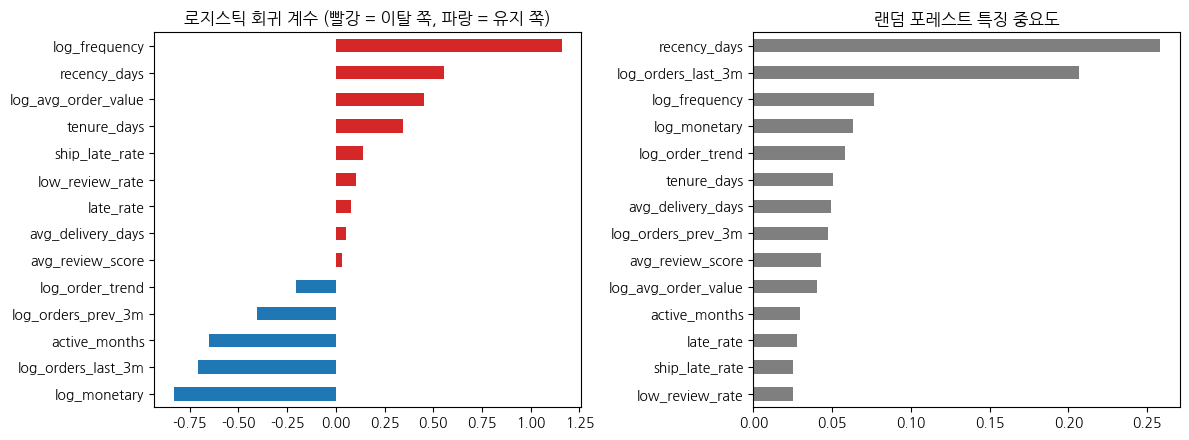

In [14]:
# 셀 14. 로지스틱 회귀 계수 + 랜덤 포레스트 중요도

# lr_model[-1] : Pipeline의 마지막 단계(모델)만 꺼내기
coef = pd.Series(lr_model[-1].coef_[0], index=features).sort_values()                              # +면 이탈 쪽
imp  = pd.Series(final["랜덤 포레스트 + balanced"][-1].feature_importances_, index=features).sort_values()   # 클수록 중요

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
coef.plot(kind="barh", ax=axes[0], color=np.where(coef > 0, "tab:red", "tab:blue"))
axes[0].set_title("로지스틱 회귀 계수 (빨강 = 이탈 쪽, 파랑 = 유지 쪽)")
imp.plot(kind="barh", ax=axes[1], color="tab:gray")
axes[1].set_title("랜덤 포레스트 특징 중요도")
plt.tight_layout(); plt.show()

**해석 포인트**
- 랜덤 포레스트는 **최근성(마지막 판매 후 일수)**과 **최근 3개월 주문 수**를 가장 중요하게 봅니다. 로지스틱 회귀에서도 두 특징이 각각 이탈 쪽(+), 유지 쪽(−)으로 크게 작용합니다. 규칙(최근 N일)이 꽤 잘 맞았던 이유입니다.
- 머신러닝은 여기에 활동 기간, 주문 추세 같은 다른 신호를 **함께 섞어** 판단합니다. 그래서 규칙보다 조금 더 낫고, 판매자마다 **이탈 확률**을 줄 수 있습니다.
- 로지스틱 회귀에서 `log_frequency`(+)와 `log_monetary`(−)가 서로 반대 방향으로 크게 나왔습니다. 두 특징이 거의 같은 정보("많이 판 판매자")를 담고 있어서 **서로 상쇄**하는 것입니다. 이렇게 비슷한 특징이 함께 있으면 계수 하나만 떼어 해석하지 말고 **묶어서** 읽습니다.
- 주문 수·금액에 로그를 씌운 이유 : 로지스틱 회귀는 직선 관계를 가정하기 때문에, 원래 값을 넣으면 주문이 수백 건인 대형 판매자의 예측이 한쪽으로 크게 끌려갑니다.

---
## 6. PART 8 판매자 유형으로 해석하기

PART 8에서 저장한 유형 모델로 이 판매자들의 유형을 붙여 봅니다. (같은 기준일, 같은 프로필 함수)

In [15]:
# 셀 15. 판매자 유형별 이탈률

# 군집에 쓰는 특징 (PART 8에서 정한 것)
seg_features = ["log_frequency", "log_monetary", "recency_days", "tenure_days", "avg_review_score"]

def make_segment_input(prof, review_fill):
    """판매자 프로필 → 군집 입력 (로그 변환 + 결측 채우기)"""
    return pd.DataFrame({
        "log_frequency":    np.log1p(prof["frequency"]),
        "log_monetary":     np.log1p(prof["monetary"]),
        "recency_days":     prof["recency_days"],
        "tenure_days":      prof["tenure_days"],
        "avg_review_score": prof["avg_review_score"].fillna(review_fill),
    })

seg_file = f"{model_path}/part8_seller_segment.pkl"
if os.path.exists(seg_file):
    seg = joblib.load(seg_file)
    Xs = make_segment_input(df, seg["review_fill"])[seg["features"]]
    df["segment"] = pd.Series(seg["kmeans"].predict(seg["scaler"].transform(Xs))).map(seg["names"])
    seg_rate = df.groupby("segment")["churn"].agg(판매자수="size", 이탈률="mean").sort_values("이탈률")
    seg_rate["이탈률"] = (seg_rate["이탈률"] * 100).round(1).astype(str) + "%"
    display(seg_rate)
else:
    print("PART 8을 먼저 실행해 part8_seller_segment.pkl을 만들어 주세요.")

,판매자수,이탈률
segment,,
핵심 우량,766,17.4%
신규 성장,750,28.1%
휴면,4,50.0%
저평점 위험,47,66.0%


In [16]:
# 셀 16. 유형을 특징으로 넣으면 성능이 오를까?

if "segment" in df.columns:
    # get_dummies : 유형 이름을 0/1 컬럼으로 바꾸기 (예: seg_핵심 우량 = 1)
    X_seg = pd.concat([X, pd.get_dummies(df["segment"], prefix="seg", dtype=int)], axis=1)
    Xs_train = X_seg.loc[X_train.index]
    base = cross_validate(make_lr("balanced"), X_train, y_train, cv=cv, scoring="f1")["test_score"]
    plus = cross_validate(make_lr("balanced"), Xs_train, y_train, cv=cv, scoring="f1")["test_score"]
    print(f"로지스틱 회귀 F1  기본 {base.mean():.3f}  →  유형 추가 {plus.mean():.3f}")

로지스틱 회귀 F1  기본 0.576  →  유형 추가 0.570


**해석**
- 유형별 이탈률은 뚜렷하게 다릅니다. 유형은 **"어떤 판매자가 위험한가"를 설명하는 데** 아주 유용합니다.
- 하지만 유형을 특징으로 넣어도 **예측 성능은 거의 오르지 않습니다.** 유형 자체가 이미 들어 있는 특징(주문 수, 판매액, 최근성, 활동 기간, 평점)으로 만든 것이라 **새로운 정보가 없기** 때문입니다.
- 이 실습의 대상은 최근 3개월에 판매가 있었던 판매자뿐이라, '휴면' 유형은 거의 없습니다.

> 💡 같은 정보를 다른 모양으로 바꿔 넣어도 모델이 새로 배울 것은 없습니다. 성능을 올리려면 **새로운 정보**(예: 문의 응답 속도, 재고, 광고 집행)가 필요합니다.

---
## 💾 배포용 저장

평가가 끝났으니, 배포할 모델은 **train + test 전체**로 다시 학습합니다. (평가용으로 떼어 둔 데이터도 학습에 쓰면 조금 더 정확해집니다)

| 저장 항목 | 역할 |
|---|---|
| `model` | 결측 채우기 → 스케일링 → 로지스틱 회귀 (Pipeline 한 덩어리) |
| `features` | 특징 이름과 순서 |
| `threshold` | 이탈 확률이 이 값 이상이면 '이탈 위험' |
| `horizon_months` | 몇 개월 뒤를 예측하는 모델인지 |

> 📌 배포 모델로 **로지스틱 회귀**를 고른 이유 : 랜덤 포레스트와 성능이 비슷한데, 파일이 몇 KB로 훨씬 작고 계수로 판단 근거를 설명하기 쉽습니다.

In [17]:
# 셀 17. 전체 데이터로 다시 학습 + 저장

deploy_model = make_lr("balanced").fit(X, y)
artifact = {"model": deploy_model, "features": features, "threshold": 0.5,
            "horizon_months": 3, "trained_cutoff": CUTOFF}
save_file = f"{model_path}/part9_seller_churn.pkl"
joblib.dump(artifact, save_file, compress=3)
print("저장 완료 :", save_file)
print(f"파일 크기 : {os.path.getsize(save_file) / 1024:.0f} KB")

# 참고 : 랜덤 포레스트를 저장하면?
rf_file = f"{model_path}/_rf_size_check.pkl"
joblib.dump(make_rf("balanced").fit(X, y), rf_file, compress=3)
print(f"(참고) 랜덤 포레스트 크기 : {os.path.getsize(rf_file) / 1024:.0f} KB")
os.remove(rf_file)

저장 완료 : /content/drive/MyDrive/Colab Notebooks/Data_Analysis/Olist/model/part9_seller_churn.pkl
파일 크기 : 2 KB
(참고) 랜덤 포레스트 크기 : 241 KB


In [18]:
# 셀 18. 저장한 파일로 예측해 보기 (STEP2 서빙에서 이렇게 사용합니다)

art = joblib.load(save_file)
sample = df.sample(5, random_state=1)                                  # 판매자 5명 뽑아 보기
prob = art["model"].predict_proba(sample[art["features"]])[:, 1]       # 이탈 확률
pd.DataFrame({"seller_id": sample["seller_id"].str[:8].values,
              "최근3개월주문": sample["orders_last_3m"].values,
              "마지막판매후일수": sample["recency_days"].values,
              "이탈확률": prob.round(3),
              "이탈위험": np.where(prob >= art["threshold"], "위험", "-"),
              "실제": np.where(sample["churn"] == 1, "이탈", "유지")})

,seller_id,최근3개월주문,마지막판매후일수,이탈확률,이탈위험,실제
0,081acf3d,2.00,8,0.48,-,이탈
1,a254c682,3.00,54,0.74,위험,유지
2,f125f3a3,4.00,16,0.35,-,유지
3,8f54d64f,4.00,26,0.43,-,유지
4,334cab71,4.00,5,0.30,-,유지


---
## 마무리 정리

| 확인할 내용 | 설명 |
|---|---|
| 이 파트의 핵심 | 과거(기준일 이전)로 특징을, 미래(이후 3개월)로 정답을 만들어 판매자 이탈을 예측했습니다. |
| 이탈 정의 | 최근 3개월 활동한 판매자가 이후 3개월 유효 주문 0건 → 실제 폐업이 아닌 **실습용 정의** |
| 베이스라인 | "최근 N일 판매 없음" 규칙도 꽤 잘 맞습니다. 머신러닝은 이보다 조금 더 낫고, 확률과 근거를 줍니다. |
| 불균형 | `class_weight="balanced"`로 재현율이 크게 오르고 정밀도는 조금 내려갑니다(맞교환). |
| 교차검증 | 데이터가 작으면 한 번의 분할 결과를 믿기 어렵습니다. 평균과 흔들림을 함께 봅니다. |
| 유형 활용 | PART 8 유형은 해석에 유용하지만, 특징으로 넣어도 성능은 오르지 않습니다(새 정보가 없음). |
| 모델 저장 | Pipeline(결측 채우기 + 스케일링 + 로지스틱 회귀)을 전체 데이터로 학습해 압축 저장 |
| 다음 단계 | PART 10에서 지금까지의 분석과 모델을 비즈니스 전략으로 연결합니다. |